Ficheros que añadir:

- Fichero D
- Fichero H
- Fichero R

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter


## Abrir ficheros de la encuesta de calidad de vida.

In [2]:
FD = pd.read_csv(r"datos\esudb25d.csv", encoding = "utf-8", low_memory = False, sep = ',')
FH = pd.read_csv(r"datos\esudb25h.csv", encoding = "utf-8", low_memory = False, sep = ',')
FR = pd.read_csv(r"datos\esudb25r.csv", encoding = "utf-8", low_memory = False, sep = ',')

### Limpieza tabla FD

#### Eliminar columnas

In [3]:
FD.drop(columns=[
    "DB020", # País todos los encuestados son de España
    "DB040_F",
    "DB090_F",
    "DB100_F"
], inplace=True) 

#### Renombrar Columnas

In [4]:
Columnas_FD = {
    "DB010": "Año",
    "DB030": "ID del Hogar",
    "DB040": "CCAA",
    "DB090": "Pesos", #Factor Trasversal del Hogar  
    "DB100": "Gurb", #Grado de urbanización
    }

### Limpieza tabla FH

##### Eliminar columnas

In [5]:
FH.drop(columns=[
    "HB050_F", "HB060_F", "HB070_F", "HB080_F", "HB100_F", "HB120_F", "HY020_F", "HY022_F", "HY023_F",
    "HY030N_F", "HY040N_F", "HY050N_F", "HY060N_F", "HY070N_F", "HY080N_F", "HY081N_F", "HY090N_F",
    "HY100N_F", "HY110N_F", "HY120N_F", "HY130N_F", "HY131N_F", "HY145N_F", "HY170N_F", "HY010_F",
    "HY040G_F", "HY050G_F", "HY060G_F", "HY070G_F", "HY080G_F", "HY081G_F", "HY090G_F", "HY100G_F",
    "HY110G_F", "HY120G_F", "HY130G_F", "HY131G_F", "HY140G_F", "HS011_F", "HS021_F", "HS022_F",
    "HS031_F", "HS040_F", "HS050_F", "HS060_F", "HS090_F", "HS110_F", "HS120_F", "HS150_F",
    "HD080_F", "HH010_F", "HH021_F", "HH030_F", "HH050_F", "HH060_F", "HH070_F", "HI010_F",
    "HS220_F", "HC006_F", "HC003A_F", "HEE07_F", "HEE01_F", "HEE09_F", "HEE11_F", "HEE13_F",
    "HEE14_F", "HEE12_F", "HS200_F", "HS210_F", "HI020_F", "HI030_F", "HI040_F", "cuotahip_F"
], inplace=True) 


In [6]:
FH.drop(columns=[
    "HB010", #Año de la encuesta (valor duplicado en FD)
    "HB020", #País (valor duplicado en FD)
    "HB050", #mes de la entrevista al hogar
    "HB060", #Año de la entrevista al hogar
    "HB070", # identificación personal del informante
    "HB080", # Identificación de la primera persona responsable de la vivienda
    "HB100", # Número de minutos empleados en cumplimentar el cuestionario del hogar,
    "HY010", # Renta bruta total del hogar en el año anterior al de encuesta
    "HY040G", #Renta bruta procedente del alquiler de una propiedad o terreno en el año anterior al de encuesta
    "HY050G", # Ayuda por familia/hijos en el año anterior al de encuesta
    "HY060G", # Ingresos por asistencia social en el año anterior al de encuesta
    "HY070G", # Ayuda para vivienda en el año anterior al de encuesta
    "HY080G", # Transferencias periódicas monetarias percibidas de otros hogares en el año anterior al de encuesta
    "HY081G", # Transferencias periódicas monetarias percibidas de otros hogares en el año anterior al de encuesta (pensiones alimenticias a hijos o compensatorias a cónyuges)
    "HY090G", # Intereses, dividendos y ganancias brutos de inversiones de capital en empresas no constituidas en sociedad en el año anterior al de encuesta
    "HY100G", # Intereses pagados del préstamo para la compra de la vivienda principal, en el año anterior al de encuesta
    "HY110G", # Renta bruta percibida por los menores de 16 años en el año anterior al de encuesta
    "HY120G", # Impuesto sobre el patrimonio en el año anterior al de encuesta. 
    "HY130G", # Transferencias periódicas monetarias abonadas a otros hogares en el año anterior al de encuesta
    "HY131G",  # Transferencias periódicas monetarias abonadas a otros hogares en el año anterior al de encuesta (pensiones alimenticias a hijos o compensatorias a cónyuges)
    "HY145N", # Devoluciones/ingresos complementarios por ajustes En impuestos en el año anterior al de encuesta (declaración del IRPF)
    "HS011", # ¿Se han producido retrasos en el pago de la hipoteca o del alquiler del hogar en los últimos 12 meses?
    'HS021', # ¿Se han producido retrasos en el pago de las facturas?
    'HS022', #¿Se benefició el hogar de algún bono social para hacer frente a gastos de electricidad, calefacción, gas, etc.?
    'HS031', # ¿Se han producido retrasos en el pago de compras aplazadas o de otros préstamos (deudas no relacionadas con la vivienda principal) en los últimos 12 meses?
    'HS040', # ¿Puede el hogar permitirse ir de vacaciones fuera de casa, al menos una semana al año?
    'HS050', # ¿Puede el hogar permitirse una comida de carne, pollo o pescado (o equivalentes para los vegetarianos) al menos cada dos días?
    'HS060', # ¿Tiene el hogar capacidad para afrontar gastos imprevistos?
    'HS090', # ¿Tiene el hogar ordenador?
    'HS110', # ¿Tiene el hogar coche?
    'HS120', # Capacidad del hogar para llegar a fin de mes
    "HS150", # Los desembolsos por compras a plazos o por devolución de préstamos no relacionados con la vivienda principal suponen para el hogar:
    'HS200', # Carga financiera de la asistencia médica
    'HS210', # Carga financiera de la asistencia dental
    'HS220', # Carga financiera de los medicamentos    
    'HC006', # Año de construcción de la vivienda
    'HC003A', # Mejoras en el aislamiento térmico o en el sistema de calefacción de la vivienda o del edificio
    'HEE07', # Razón principal por la que no se ha mejorado la eficiencia energética
    'HEE01', # Distancia a pie desde su casa hasta el espacio verde público más cercano
    'HEE09', # ¿Se reciclan las botellas de plástico?
    'HEE11', # Número de vehículos de los que dispone el hogar de uso regular como medio de transporte personal
    'HEE13', # Antigüedad del vehículo más nuevo (o del único)
    'HEE14', # Antigüedad del vehículo más viejo
    'HEE12', # Tipo de combustible que utiliza el vehículo más nuevo (o el único)
    'HD080', # ¿El hogar podría sustituir los muebles estropeados o viejos?
    'HH010', # Tipo de vivienda
    'HH021', # Régimen de tenencia
    'HH030', # Número de habitaciones de la vivienda
    'HH050', # ¿Puede el hogar permitirse mantener la vivienda con una temperatura adecuada durante los meses de invierno?  
    'HH070', # Gastos de la vivienda: Alquiler (si la vivienda se encuentra en régimen de alquiler), intereses de la hipoteca (para viviendas en propiedad con pagos pendientes) y otros gastos asociados (comunidad, agua, electricidad, gas, etc.)
    'HI010', # ¿Se ha producido un cambio en los ingresos del hogar en los últimos 12 meses?
    'HI020', # ¿Cuál ha sido el motivo principal del aumento de los ingresos?
    'HI030', # ¿Cuál ha sido el motivo principal de la disminución de los ingresos?
    'HI040' # Pensando en los ingresos de su hogar, ¿qué espera que pase en los próximos 12 meses?  
], inplace =True)

#### Renombre de columnas

In [7]:
Columnas_FH = {
    "HB120" : "N_miembros", #Número de miembros del hogar
    "HY020" : "Renta disponible",
    "HY022" : "rdantr", # Renta disponible total antes de transferencias excepto prestaciones por jubilación y por supervivencia
    "HY023" : "rdantrinjs", # Renta disponible total antes de transferencias incluidas prestaciones por jubilación y por supervivencia
    "HY030N" : "alqimput", #alquiler imputado
    "HY040N" : "rnalquiler", # Renta neta procedente del alquiler de una propiedad o terreno
    "HY050N" : "ayufam", # Ayuda por familia/ hijos"
    "HY060N" : "asissocial", # Ingresos por asistencia social
    "HY070N" : "ayuvivienda", # Ayuda para vivienda
    "HY080N" : "transhogares", # Transferencias periódicas monetarias percibidas de otros hogares
    "HY081N" : "transaliment", # Transferencias periódicas monetarias percibidas de otros hogares en el año anterior al de encuesta (pensiones alimenticias a hijos o compensatorias a cónyuges)
    "HY090N" : "inver", # Intereses, dividendos y ganancias netos de inversiones de capital en empresas no constituidas en sociedad
    "HY100N" : "intvivienda", # Intereses pagados del préstamo para la compra de la vivienda principal
    "HY110N" : "rent<16", # Renta neta percibida por los menores de 16 años
    "HY120N" : "imppn", # Impuesto sobre el patrimonio
    "HY130N" : "transhogaresrest", # Transferencias periódicas monetarias abonadas a otros hogares
    "HY131N" : "transalimentrest", # ransferencias periódicas monetarias abonadas a otros hogares en el año anterior al de encuesta (pensiones alimenticias a hijos o compensatorias a cónyuges)
    "HY170N" : "Autocon", # Autoconsumo en el año anterior al de encuesta
    "HY140G" : "imprent", # Impuesto sobre la renta y cotizaciones sociales
    "HH060" : "Alquiler", # Alquiler actual por la vivienda ocupada
    "cuotahip": "cuotahip", # Cuota hipotecaria
    "HX040" : "miembros", # Número de miembros del hogar
    "HX240" : "uccons", # Unidades de consumo Escala OCDE"
    "vhRentaa" : "vhRentaa", # Renta disponible total del hogar
    "vhRentaAIa" : "vhRentaAIa", #Renta disponible total del hogar incluyendo alquiler imputado
    "vhPobreza" : "vhPobreza", # Hogar en riesgo de pobreza
    "vhMATDEP" : "vhMATDEP", # Hogar en carencia material severa.
    }

Cambiar el tipo de las variables


In [8]:
FH["HH060"] = pd.to_numeric(FH["HH060"], errors="coerce")

### Limpieza tabla FR

#### Eliminar Columnas

In [9]:
FR.drop(columns = [
    'RB050_F', 'RB080_F', 'RB081_F', 'RB082_F', 'RB090_F', 'RB200_F', 'RB211_F', 'RB220_F',
    'RB230_F', 'RB240_F', 'RB280_F', 'RB290_F', 'RL010_F', 'RL020_F', 'RL030_F', 'RL040_F',
    'RL050_F', 'RL060_F', 'RL070_F'
], inplace = True)

In [10]:
FR.drop(columns = [
'RB010', # año de la encuesta
'RB020', # País
'RB082', # Edad de la fecha de la entrevista
'RB200', # Situación respecto a la residencia en el hogar 
'RB220', # Identificador del padre 
'RB230', # Identificador de la madre 
'RB240', # Identificador del cónyuge o pareja
'RL010', # Número de horas en una semana normal que ha sido cuidado o ha asistido a centros de educación preescolar o infantil
'RL020', # Número de horas en una semana normal que ha sido cuidado en centros de educación obligatoria (primaria o secundaria)
'RL030', # Número de horas en una semana normal que ha sido cuidado en centros de cuidado de niños fuera del horario escolar (antes o después del horario escolar aunque sea dentro del mismo centro)
'RL040', # Número de horas en una semana normal que ha sido cuidado en otros centros de cuidado de niños
'RL050', # Número de horas en una semana normal que ha sido cuidado por cuidadores profesionales remunerados en casa del niño o del cuidador (niñeras, asistentas, etc.)
'RL060', # Número de horas en una semana normal que ha sido sido cuidado por otras personas sin remunerar (abuelos, otros miembros que no sean los padres, otros parientes, amigos, vecinos etc.)
'RL070', # Peso transversal para los niños (para el cuidado de niños) 
'vrLOWJOB', # Personas en hogares sin empleo o con baja intensidad en el empleo (estrategia Europa 2020)
'vrEU2020', # Personas en riesgo de pobreza o exclusión social (estrategia Europa 2020).
'vrMATSOCDEP', # Personas en carencia material y social severa
'vrLOWJOB_nuevo', # Personas en hogares sin empleo o con baja intensidad en el empleo (objetivo Europa 2030)
'vrEU2030_nuevo' # Personas en riesgo de pobreza o exclusión social (objetivo Europa 2030).
], inplace = True)

In [11]:
Columnas_FR = {
    'RB030' : "ID de la persona", # Identificador trasversal de la persona (DB030 + nº en dos dígitos, de la persona dentro del hogar)
    'RB050' : "factor_r", # Factor ponderación trasversa
    'RB080' : "a_nacimiento", # Año de nacimiento
    'RB081' : "edad", # Edad a 31 de Diciembre del año anterior a la encuesta.
    'RB090' : "genero", # Sexo
    'RB280' : "p_nacimiento", # Pais de nacimiento
    'RB290' : "nacionalidad", # Nacionalidad
    'RB211': "act_laboral", # Situación de la actividad 
}

### Unión de los dataframes FD y FH

In [12]:
FD.head()

,DB010,DB030,DB040,DB090,DB100
0,2025,1,ES21,623.81237,3
1,2025,2,ES21,279.26707,3
2,2025,3,ES21,719.41894,3
3,2025,4,ES21,261.64358,3
4,2025,5,ES21,655.08727,3


In [13]:
Datos = FD.merge(
    FH,
    how ='left',
    left_on="DB030",
    right_on="HB030").drop(columns = [
        "HB030"])


In [14]:
Datos = Datos.rename(columns = Columnas_FD)
Datos = Datos.rename(columns = Columnas_FH)
FR = FR.rename(columns = Columnas_FR)

## Sustituir valores de las variables categóricas

#### Variable DB040 CCAA

In [15]:
ccaa = {
    "ES11": "Galicia",
    "ES12": "Asturias",
    "ES13": "Cantabria",
    "ES21": "País Vasco",
    "ES22": "C.F. de Navarra",
    "ES23": "La Rioja",
    "ES24": "Aragón",
    "ES30": "C.Madrid",
    "ES41": "Castilla y León",
    "ES42": "Castilla-La Mancha",
    "ES43": "Extremadura",
    "ES51": "Cataluña",
    "ES52": "C.Valenciana",
    "ES53": "Islas Baleares",
    "ES61": "Andalucía",
    "ES62": "Región de Murcia",
    "ES63": "C.A. de Ceuta",
    "ES64": "C.A. de Melilla",
    "ES70": "Canarias"
}


In [16]:
Datos["CCAA"] = Datos["CCAA"].map(ccaa)

#### Variable DB100 Grado de urbanización 

In [17]:
G_urbanizacion = {
    1 : "Zona muy poblada",
    2 : "Zona media",
    3 : "Zona poco poblada"
}

In [18]:
Datos["Gurb"] = Datos["Gurb"].map(G_urbanizacion)

#### Variable RB090 Genero

In [19]:
Genero = {
    1 : "Hombre",
    2 :	"Mujer"
}


In [20]:
FR["genero"] = FR["genero"].map(Genero)

#### Variable RB290 Nacionalidad

In [21]:
Nacionalidad = {
    1 : "España",
    2 : "Extranjera UE",
    3 : "Extranjera RM"
}

In [22]:
FR["nacionalidad"] = FR["nacionalidad"].map(Nacionalidad)

## Crear Funciones

In [ ]:
def mediana_ponderada (valores: float, peso: float) ->[float]: #calcula la mediana teniendo encuenta el peso
    df = pd.DataFrame({
        "valor": valores, #valor del que se quiere calcular la mediana
        "peso": peso # peso a usar
    }).dropna().sort_values("valor") # ordenar los valores de menor a mayor

    peso_acum = df["peso"].cumsum() # calcular la suma acumulada después de ordenar la muestra por el valor de menor a mayor 

    return df.loc[
        peso_acum >= (df["peso"].sum()) / 2 , # filtrame las filas donde el peso acumulado sea mayor o igual al 50%
        "valor"
    ].iloc[0] #filtrame el primer valor 

In [ ]:
def Gini_ponderado (renta:float, poblacion:float) -> [float]: #calcular el índide Gini de una variable
    """
    G = |1 − ∑(k=1 a n−1) (Xk+1 − Xk)(Yk+1 + Yk)|
    Donde:
    X = Proporcíon acumulada de la variable población
    Y = Proporción acumulada de la variable ingresos"""

    renta = np.asarray(renta, dtype=float)
    poblacion = np.asarray(poblacion, dtype=float)

    # Eliminar valores no válidos y pesos negativos
    valido = (
        np.isfinite(renta) &
        np.isfinite(poblacion) &
        (poblacion > 0) &
        (renta >= 0)
    )

    renta = renta[valido]
    poblacion = poblacion[valido]

    if len(renta) == 0:
        return np.nan

    # Ordenar las rentas de menor a mayor
    orden = np.argsort(renta)
    renta = renta[orden]
    poblacion = poblacion[orden] # ordenar la matriz de población por las rentas de menor a mayor

    # Población y renta acumuladas ponderadas
    pob_ac = np.cumsum(poblacion) / np.sum(poblacion)

    renta_pond = renta * poblacion 
    renta_ac = np.cumsum(renta_pond) / np.sum(renta_pond)

    # Añadir el origen de la curva de Lorenz
    pob_ac = np.insert(pob_ac, 0, 0)
    renta_ac = np.insert(renta_ac, 0, 0)

    # Área bajo la curva de Lorenz
    area = np.trapezoid(renta_ac, pob_ac)

    # Índice de Gini
    Gini = 1 - 2 * area

    return Gini.round(3)


In [25]:
def cuantiles_ponderados(renta: float, pesos: float, cuantiles=[0.25, 0.50, 0.75]) -> [float]: 

    renta = np.asarray(renta)
    pesos = np.asarray(pesos)

    orden = np.argsort(renta) # devuelve las posiciones indices de un array ordenado de menor a mayor 
    renta = renta[orden] #ordenamos las rentas de menor a mayor
    pesos = pesos[orden] # ordenamos los pesos exactamente con el mismo orden de las rentas

    acumulado = np.cumsum(pesos) / np.sum(pesos) # el porcentaje de la población ordenador desde la renta de menor a mayor

    return np.interp(cuantiles, acumulado, renta) # np.interp calcula la renta (y) del quantil (x) teninendo en cuenta los pesos acumulados (acumulado) tiene en cuneta que la relación es lineal

In [26]:
def deciles_ponderados(renta, pesos, deciles = np.arange(0.1, 1.0, 0.1)):

    renta = np.asarray(renta)
    pesos = np.asarray(pesos)

    orden = np.argsort(renta) # devuelve las posiciones indices de un array ordenado de menor a mayor 
    renta = renta[orden] #ordenamos las rentas de menor a mayor
    pesos = pesos[orden] # ordenamos los pesos exactamente con el mismo orden de las rentas

    acumulado = np.cumsum(pesos) / np.sum(pesos) # el porcentaje de la población ordenador desde la renta de menor a mayor

    return np.interp(deciles, acumulado, renta) # np.interp calcula la renta (y) del quantil (x) teninendo en cuenta los pesos acumulados (acumulado) tiene en cuneta que la relación es lineal

## Crear variables

In [27]:
Datos.insert(
    len(Datos.columns),
    "Factor",
    Datos["Pesos"].mul(Datos["miembros"])
) # De esta forma podremos estudiar las personas en vez de los hogares calculando el peso ponderado del individuo

In [28]:
Datos.insert(
    len(Datos.columns),
    "rentapc",
    Datos["vhRentaa"].div(Datos["miembros"])
    # renta anual per cápita
)

In [29]:
Datos.insert(
    len(Datos.columns),
    "rocdem",
    Datos["vhRentaa"].div(Datos["uccons"])
    # renta anual per capita con la escala OCDE
)

In [30]:
Datos.insert(
    len(Datos.columns),
    "rentapcAI",
    Datos["vhRentaAIa"].div(Datos["miembros"])
    # renta anual per capita incluyendo alquiler imputado
)

In [31]:
Datos.insert(
    len(Datos.columns),
    "rocdemAI",
    Datos["vhRentaAIa"].div(Datos["uccons"])
    # renta per capita del hogar incluyendo alquiler imputado
)

In [32]:
Deciles = deciles_ponderados(
    Datos["rocdem"],
    Datos["Factor"]
)


Condiciones = [
    Datos["rocdem"] <= Deciles[0],
    Datos["rocdem"] <= Deciles[1],
    Datos["rocdem"] <= Deciles[2],
    Datos["rocdem"] <= Deciles[3],
    Datos["rocdem"] <= Deciles[4],
    Datos["rocdem"] <= Deciles[5],
    Datos["rocdem"] <= Deciles[6],
    Datos["rocdem"] <= Deciles[7],
    Datos["rocdem"] <= Deciles[8]
]

Datos.insert(
    len(Datos.columns),
    "Decil_d",
    np.select(
        Condiciones,
        [1, 2, 3, 4, 5, 6, 7, 8, 9],
        default = 10
    )
)

### FR

In [33]:
FR.insert(
    0,
    "ID del Hogar_r",
    FR["ID de la persona"] // 100
    
)

In [34]:
FR = FR.merge(
    Datos[["ID del Hogar", "CCAA"]], 
    how = "left",
    left_on = "ID del Hogar_r",
    right_on = "ID del Hogar"
).drop(columns = ["ID del Hogar"])

In [35]:
FR = FR.merge(
    Datos[["ID del Hogar", "rocdem", "rentapc"]],
    how="left",
    left_on="ID del Hogar_r",
    right_on="ID del Hogar",
    validate="many_to_one"
).drop(columns = ["ID del Hogar"])

In [36]:
rangos = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45,
          50, 55, 60, 65, 70, 75, 80, float("inf")]

etiquetas = ["0-4", "5-9", "10-14", "15-19", "20-24",
             "25-29", "30-34", "35-39", "40-44", "45-49",
             "50-54", "55-59", "60-64", "65-69", "70-74",
             "75-79", "+80"]


FR.insert(
    4,
    "rango_edad",
    pd.cut(FR["edad"], bins = rangos, labels = etiquetas)

)

# Análisis

## Demográfico

Población por Comunidades autónomas

In [37]:
Pob_CCAA = (
    Datos.groupby("CCAA")["Factor"]
    .sum()
    .round(0)
    .reset_index(name = "Población")
    .sort_values(by ="Población", ascending = False)
    .reset_index(drop = True)
)

Pob_CCAA["Peso (%)"] = (
    Pob_CCAA["Población"] / Pob_CCAA["Población"].sum() * 100
)
Pob_CCAA.loc[len(Pob_CCAA)] = [
    "Total",
    Pob_CCAA["Población"].sum(),
    Pob_CCAA["Peso (%)"].sum()
]

Pob_CCAA.style.format({
    "Población": lambda x: f"{x:,.0f}".replace(",", "."),
    "Peso (%)" : lambda x: f"{x:.2f}".replace(".", ",") + "%"
})



,CCAA,Población,Peso (%)
0,Andalucía,8.616.362,"17,69%"
1,Cataluña,8.032.211,"16,49%"
2,C.Madrid,7.073.299,"14,52%"
3,C.Valenciana,5.380.089,"11,05%"
4,Galicia,2.693.612,"5,53%"
5,Castilla y León,2.374.260,"4,88%"
6,Canarias,2.244.975,"4,61%"
7,País Vasco,2.218.803,"4,56%"
8,Castilla-La Mancha,2.107.209,"4,33%"
9,Región de Murcia,1.575.611,"3,24%"


C:\Users\USER\AppData\Local\Temp\ipykernel_11696\3323050272.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


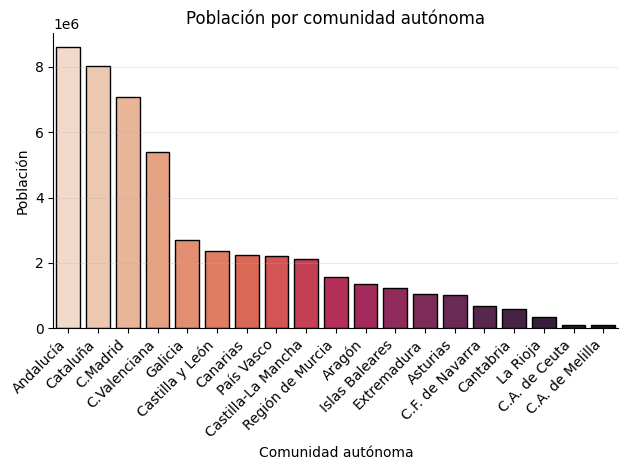

In [38]:
Datos_Grafico = Pob_CCAA[Pob_CCAA["CCAA"] != "Total"][["CCAA", "Población"]]

fig, ax = plt.subplots()

ax = sns.barplot(
    Datos_Grafico,
    x = "CCAA",
    y = "Población",
    palette = sns.color_palette("rocket_r", n_colors=len(Datos_Grafico)),
    edgecolor = "black",
    legend = False
)

ax.set_title("Población por comunidad autónoma")
ax.set_xlabel("Comunidad autónoma")
ax.set_ylabel("Población")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.grid(axis="y", alpha=0.25)
plt.show()

fig.savefig(
    "G Demografía /Poblacion_CCAA.png",
    dpi=300,
    bbox_inches="tight"
)

### Zona urbanización

La categoría que da el INE sobre las zonas de urbanización:

- Zonas densamente pobladas (ciudades): Áreas con una alta concentración de 
población y un entorno urbano muy desarrollado. Tienen una densidad de población 
superior a 1.500 habitantes por kilómetro cuadrado y un total de al menos 50.000 
habitantes.

- Zonas de densidad intermedia (suburbios o pueblos): Estas áreas incluyen 
suburbios o pueblos donde la densidad de población es moderada. Generalmente 
tienen entre 300 y 1.500 habitantes por kilómetro cuadrado, con una población 
mínima de 5.000 habitantes.

- Zonas escasamente pobladas (rurales): Áreas con una baja densidad de 
población, típicamente inferior a 300 habitantes por kilómetro cuadrado. Predominan 
en entornos rurales, con menos desarrollo urbano y servicios.

In [39]:
Pob_gurb = (
    Datos.groupby("Gurb")["Factor"]
    .sum()
    .round(0)
    .reset_index(name = "Población")
    .sort_values(by ="Población", ascending = False)
    .reset_index(drop = True)
)

Pob_gurb["Peso (%)"] = (
    Pob_gurb["Población"] / Pob_gurb["Población"].sum() * 100
)
Pob_gurb.loc[len(Pob_gurb)] = [
   "Total",
    Pob_gurb["Población"].sum(),
    Pob_gurb["Peso (%)"].sum()
]

Pob_gurb.style.format({
    "Población": lambda x: f"{x:,.0f}".replace(",", "."),
    "Peso (%)" : lambda x: f"{x:.2f}".replace(".", ",") + "%"
})



,Gurb,Población,Peso (%)
0,Zona muy poblada,26.053.498,"53,50%"
1,Zona media,15.906.749,"32,66%"
2,Zona poco poblada,6.741.937,"13,84%"
3,Total,48.702.184,"100,00%"


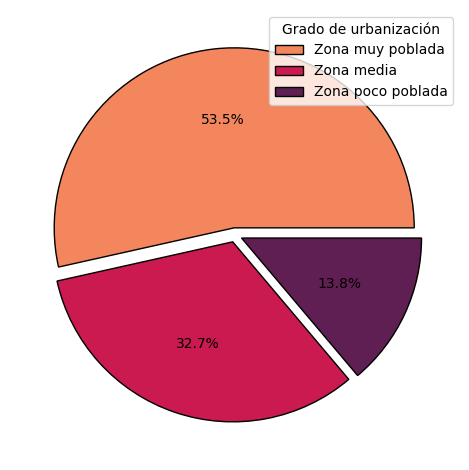

In [84]:
fig, ax = plt.subplots()

Datos_Pie = Pob_gurb[Pob_gurb["Gurb"] != "Total"]

wedges, texts, autotexts = plt.pie(
    Datos_Pie["Población"],
    autopct = "%1.1f%%",
    colors = sns.color_palette(
        "rocket_r",
        n_colors=len(Datos_Pie)),
    explode=[0.04] * len(Datos_Pie),
    wedgeprops = {"edgecolor" : "black"}
    )

ax.legend(
    wedges,
    Datos_Pie["Gurb"],
    title="Grado de urbanización"
)
# ax.set_title("Población por grado de urbanización")
plt.tight_layout()

plt.show()

fig.savefig(
    "G Demografía /Poblacion_Gurb.png",
    dpi=300,
    bbox_inches="tight"
)

CCAA con mayor población viviendo en zonas poco pobladas

In [41]:
Pob_Poco_poblada = (
    Datos.groupby(["CCAA", "Gurb"])["Factor"]
    .sum()
    .loc[(slice(None), "Zona poco poblada")]
    .sort_values(ascending=False)
    .to_frame(name="Población")
    .head(1)
)

Pob_Poco_poblada.style.format({
    "Población": lambda x: f"{x:,.0f}".replace(",", ".")
})

,Población
CCAA,
Andalucía,1.187.255


CCAA con mayor frecuencia de población viviendo en zonas poco pobladas


In [42]:
Pob_CCAA_Grurb = (
    Datos.groupby(["CCAA", "Gurb"], as_index=False)["Factor"].sum()
    .rename(columns={"Factor": "Población"})
    .assign(**{"Peso_Grub (%)": lambda df:
        (df["Población"] / df.groupby("CCAA")["Población"].transform("sum") * 100).round(2)
    })
)

Pob_CCAA_Grurb.loc[
    Pob_CCAA_Grurb["Gurb"] == "Zona poco poblada"
].nlargest(1, "Peso_Grub (%)").style.format({
     "Población": lambda x: f"{x:,.0f}".replace(",", "."),
    "Peso_Grub (%)" : lambda x: f"{x:.2f}".replace(".", ",") + "%" 

})

,CCAA,Gurb,Población,Peso_Grub (%)
28,Castilla y León,Zona poco poblada,860.245,"36,23%"


la población dependiendo de la zona donde viva, dentro de la población total de cada CCAA


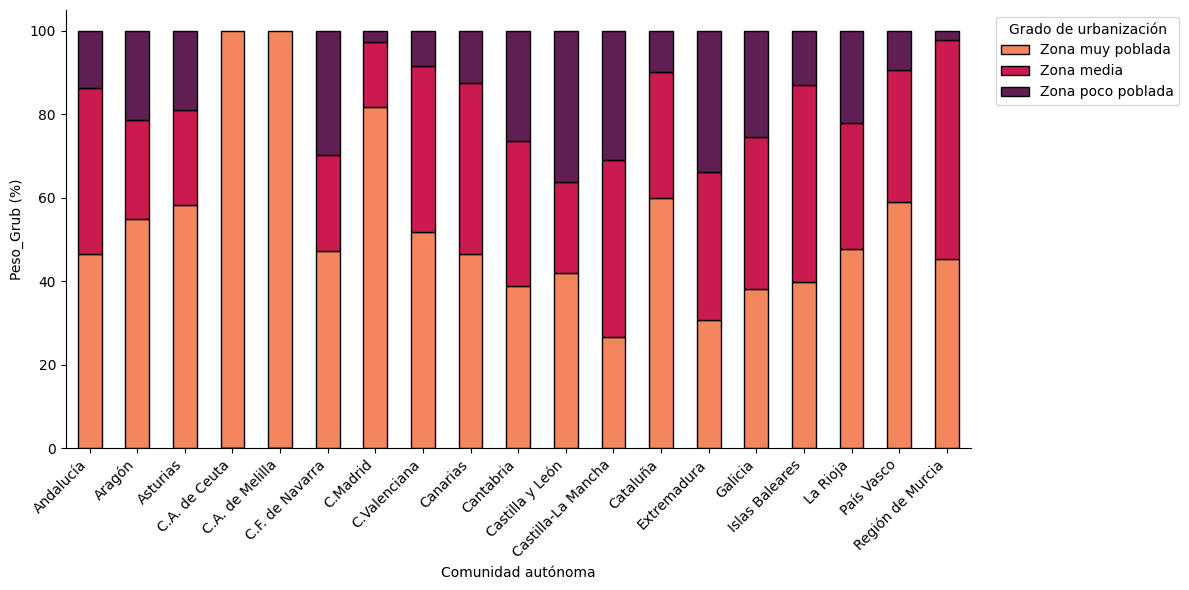

In [86]:
Datos_Grafico = Pob_CCAA_Grurb.pivot(
    index="CCAA",
    columns="Gurb",
    values="Peso_Grub (%)"
)

# Orden de abajo hacia arriba
orden = [
    "Zona muy poblada",
    "Zona media",
    "Zona poco poblada"
]

Datos_Grafico = Datos_Grafico[orden]

fig, ax = plt.subplots(figsize=(12, 6))

Datos_Grafico.plot(
    kind="bar",
    stacked=True,
    color=sns.color_palette(
        "rocket_r",
        n_colors=len(Datos_Grafico.columns)
    ),
    edgecolor = "black",
    ax=ax
)

#ax.set_title("Población por CCAA y grado de urbanización")
ax.set_xlabel("Comunidad autónoma")
ax.set_ylabel("Peso_Grub (%)")

ax.legend(
    title="Grado de urbanización",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

fig.savefig(
    "G Demografía /Poblacion_por_Urb_CCAA.png",
    dpi=300,
    bbox_inches="tight"
)

Podemos ver que las personas en España según el tipo de urbanización suelen vivir en zonas muy pobladas (53,5% de la población). Por otro lado, vemos que la CCAA con mayor peso en su población que vive en zonas poco pobladas es Castilla y León, donde un 36,23% de su población vive en zonas de baja densidad, aunque Andalucía es la comunidad autónoma con mayor población viviendo en zonas poco pobladas.

### Edad y Genero de la población

#### Genero

In [44]:
(FR.groupby("genero")["factor_r"].sum()
 .div(FR["factor_r"].sum())
 .mul(100)
 .round(2)
 .map(lambda x : f"{x:.2f}".replace(".", ",") + "%")
 )

genero
Hombre    49,05%
Mujer     50,95%
Name: factor_r, dtype: object

In [45]:
FR["Peso genero (%)"] =  (FR["factor_r"] / FR.groupby("CCAA")["factor_r"].transform("sum"))*100

Gen_CCAA = pd.pivot_table(
    FR,
    values = ["factor_r", "Peso genero (%)"],
    index = "CCAA",
    columns = "genero",
    aggfunc = {
        "factor_r" : "sum",
        "Peso genero (%)" : "sum"
    }
).reset_index()

Gen_CCAA.loc[len(Gen_CCAA)] = {
    ("CCAA", "") : "Total",

    ("Peso genero (%)", "Hombre"): FR.loc[
        FR["genero"] == "Hombre", "factor_r"].sum() / FR["factor_r"].sum() * 100,
    ("Peso genero (%)", "Mujer"): FR.loc[
        FR["genero"] == "Mujer", "factor_r"].sum() / FR["factor_r"].sum() * 100,

    ("factor_r", "Hombre"): FR.loc[
        FR["genero"] == "Hombre", "factor_r"].sum(),
    ("factor_r", "Mujer"): FR.loc[
        FR["genero"] == "Mujer", "factor_r"].sum()
    
}


Gen_CCAA = Gen_CCAA.swaplevel(0, 1, axis = 1).sort_index(axis = 1)

FR.drop(columns = ["Peso genero (%)"])

Gen_CCAA.style.format({
    ("Hombre", "factor_r"): lambda x: f"{x:,.0f}".replace(",", "."),
    ("Hombre", "Peso genero (%)"): lambda x: f"{x:.2f}".replace(".", ",") + "%",
    ("Mujer", "factor_r"): lambda x: f"{x:,.0f}".replace(",", "."),
    ("Mujer", "Peso genero (%)"): lambda x: f"{x:.2f}".replace(".", ",") + "%"
})


#### Edad

In [106]:
EDAD = FR[FR["edad"] != -1]

Media_edad = np.average(EDAD["edad"], weights = EDAD["factor_r"])
Varianza_edad = np.average((EDAD["edad"] - Media_edad)** 2, weights = EDAD["factor_r"])
DT_edad = np.sqrt(Varianza_edad)
Minimo_edad = EDAD["edad"].min()
Máximo_edad = EDAD["edad"].max()

Descriptivos = pd.Series({
    "Población": f"{EDAD['factor_r'].sum():,.0f}".replace(",", "."),
    "Edad Media": f"{Media_edad:.2f}".replace(".", ","),
    "Desviación típica": f"{DT_edad:.2f}".replace(".", ",")
})

Descriptivos

Población            48.644.805
Edad Media                43,86
Desviación típica         22,61
dtype: object

In [124]:
EDAD_M_CCAA = EDAD.groupby("CCAA").apply(
        lambda x:pd.Series(
            np.average(
                x["edad"],
                weights = x["factor_r"]
            ),
            index=["Edad Media"]
        )
    ).round(2).sort_values(by = "Edad Media", ascending = False).reset_index()

EDAD_M_CCAA.loc[len(EDAD_M_CCAA)] = {
    "CCAA" : "Total",
    "Edad Media": Media_edad.round(2)
}
EDAD_M_CCAA

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\1734150811.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  EDAD_M_CCAA = EDAD.groupby("CCAA").apply(


,CCAA,Edad Media
0,Asturias,48.95
1,Galicia,47.75
2,Castilla y León,47.64
3,Cantabria,46.25
4,País Vasco,45.67
5,Extremadura,45.41
6,La Rioja,44.87
7,Aragón,44.84
8,Canarias,43.73
9,C.F. de Navarra,43.58


### Nacionalidad

In [47]:
FR.groupby("nacionalidad")["factor_r"].sum().map(
    lambda x: f"{x:,.0f}".replace(",", "."))

nacionalidad
España           41.955.760
Extranjera RM     4.679.584
Extranjera UE     2.066.840
Name: factor_r, dtype: object

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\339944067.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  Piramide_n_esp = pd.pivot_table(


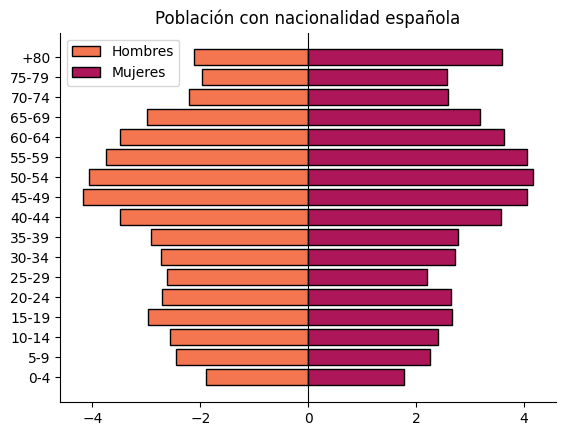

In [107]:
# Crear tabla
Piramide_n_esp = pd.pivot_table(
    EDAD[EDAD["nacionalidad"] == "España"],
    values = "factor_r",
    index = "rango_edad",
    columns = "genero",
    aggfunc = "sum",    
)
# Pasar los datos a datos procentuales sobre el total de la población
Total_n_esp = Piramide_n_esp.sum().sum()
Hombres_n_esp = (- Piramide_n_esp["Hombre"]).div(Total_n_esp).mul(100)
Mujeres_n_esp = Piramide_n_esp["Mujer"].div(Total_n_esp).mul(100)


fig, ax = plt.subplots()

ax.barh(
    y = Piramide_n_esp.index.astype(str),
    width = Hombres_n_esp,
    color = "#F37651",
    edgecolor = "black",
    label = "Hombres"
)



ax.barh(
    y = Piramide_n_esp.index.astype(str),
    width =  Mujeres_n_esp,
    color = "#AD1759",
    edgecolor = "black",
    label = "Mujeres"
)

ax.axvline(0, color="black", linewidth=0.8)
ax.yaxis.set_ticks_position("left")


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("Población con nacionalidad española")
ax.legend()

fig.savefig(
    "G Demografía /piramide poblacional.png",
    dpi=300,
    bbox_inches="tight"
)

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\1849106940.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  Piramide_n_ext = pd.pivot_table(


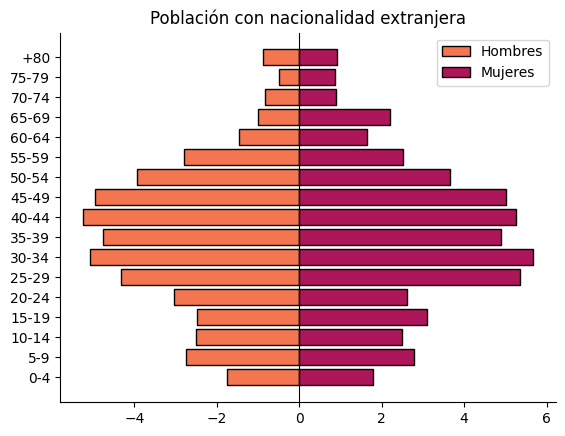

In [93]:

# Crear tabla
Piramide_n_ext = pd.pivot_table(
    FR[FR["nacionalidad"] != "España"],
    values = "factor_r",
    index = "rango_edad",
    columns = "genero",
    aggfunc = "sum",    
)


# Pasar los datos a datos procentuales sobre el total de la población
Total_n_ext = Piramide_n_ext.sum().sum()
Hombres_n_ext = (- Piramide_n_ext["Hombre"]).div(Total_n_ext).mul(100)
Mujeres_n_ext = Piramide_n_ext["Mujer"].div(Total_n_ext).mul(100)

fig, ax = plt.subplots()

ax.barh(
    y = Piramide_n_ext.index.astype(str),
    width = Hombres_n_ext,
    color = "#F37651",
    edgecolor = "black",
    label = "Hombres"
)

ax.barh(
    y = Piramide_n_ext.index.astype(str),
    width =  Mujeres_n_ext,
    color = "#AD1759",
    edgecolor = "black",
    label = "Mujeres"
)

ax.axvline(0, color="black", linewidth=0.8)
ax.yaxis.set_ticks_position("left")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("Población con nacionalidad extranjera")
ax.legend()

fig.savefig(
    "G Demografía /piramide poblacional extranjeros.png",
    dpi=300,
    bbox_inches="tight"
)

In [50]:
FR["Peso_pob (%)"] = (FR["factor_r"] / FR.groupby("CCAA")["factor_r"].transform("sum")).mul(100)

Pob_nacionalidad = pd.pivot_table(
    FR,
    values = ["factor_r", "Peso_pob (%)"],
    index = "CCAA",
    columns = "nacionalidad",
    aggfunc = {
        "factor_r" : "sum",
        "Peso_pob (%)" : "sum"
    }
).reset_index()

FR.drop(columns = ["Peso_pob (%)"])

Pob_nacionalidad.loc[len(Pob_nacionalidad)] = {
    ("CCAA", "") : "Total",

    ("Peso_pob (%)", "España") : FR.loc[
        FR["nacionalidad"] == "España", "factor_r"].sum() / FR["factor_r"].sum() * 100,
    ("Peso_pob (%)", "Extranjera UE"): FR.loc[
        FR["nacionalidad"] == "Extranjera UE", "factor_r"].sum() / FR["factor_r"].sum() * 100,
    ("Peso_pob (%)", "Extranjera RM"): FR.loc[
        FR["nacionalidad"] == "Extranjera RM", "factor_r"].sum() / FR["factor_r"].sum() * 100,


    ("factor_r", "España"): FR.loc[
        FR["nacionalidad"] == "España", "factor_r"
    ].sum(),
    ("factor_r", "Extranjera UE"): FR.loc[
        FR["nacionalidad"] == "Extranjera UE", "factor_r"
    ].sum(),
    ("factor_r", "Extranjera RM"): FR.loc[
        FR["nacionalidad"] == "Extranjera RM", "factor_r"
    ].sum(),

}

Pob_nacionalidad = Pob_nacionalidad.swaplevel(0, 1, axis = 1).sort_index(axis = 1)

Pob_nacionalidad.style.format({
    ("España", "factor_r"): lambda x: f"{x:,.0f}".replace(",", "."),
    ("España", "Peso_pob (%)"): lambda x: f"{x:.2f}".replace(".", ",") + "%",
    ("Extranjera UE", "factor_r"): lambda x: f"{x:,.0f}".replace(",", "."),
    ("Extranjera UE", "Peso_pob (%)"): lambda x: f"{x:.2f}".replace(".", ",") + "%",
    ("Extranjera RM", "factor_r"): lambda x: f"{x:,.0f}".replace(",", "."),
    ("Extranjera RM", "Peso_pob (%)"): lambda x: f"{x:.2f}".replace(".", ",") + "%"
})

In [125]:
with pd.ExcelWriter("Tablas/Resultados_Dmografia_ECV.xlsx") as writer:

    Pob_CCAA.to_excel(
            writer,
            sheet_name = "Pob_CCAA",
            index=False
        )

    Pob_gurb.to_excel(
            writer,
            sheet_name = "Pob_gurb",
            index=False
        )

    Gen_CCAA.to_excel(
            writer,
            sheet_name = "Gen_CCAA",
            index=True
        )

    Pob_nacionalidad.to_excel(
            writer,
            sheet_name = "Pob_nacionalidad",
            index=True
        )

    EDAD_M_CCAA.to_excel(
        writer,
        sheet_name = "Edad_media_CCAA",
        index = False
    )


## Desigualdad y pobreza

### Desigualda y distribución de la renta

Al ser los datos una muestra y al querer visualizar los datos poblacionales. Tendremos que tener en cuenta la varaible factor, como peso que tiene el individuo en la muestra respecto a la población total. Es por ello que todas las medidas tendremos que utilizar un factor de ponderación.

Renta Media Per Capita

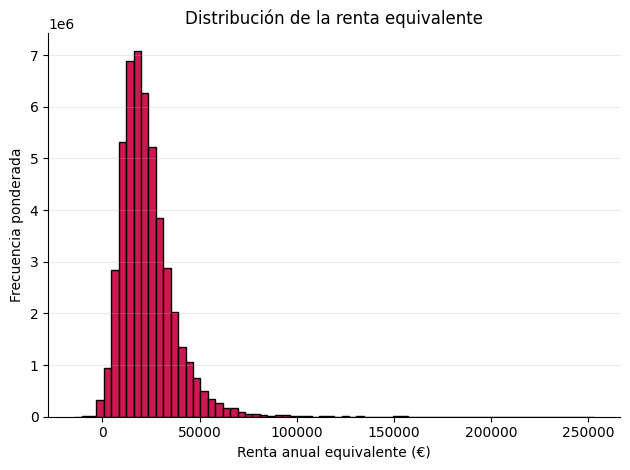

In [148]:
fig, ax = plt.subplots()

ax.hist(
    Datos["rocdem"],
    bins=70,
    weights=Datos["Factor"],
    color=sns.color_palette("rocket_r", n_colors=1)[0],
    edgecolor="black"
)

ax.set_title("Distribución de la renta equivalente")
ax.set_xlabel("Renta anual equivalente (€)")
ax.set_ylabel("Frecuencia ponderada")

ax.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

fig.savefig(
    "G Renta / histograma.png",
    dpi=300,
    bbox_inches="tight"
)


In [144]:
Renta_media_pc = ((Datos["rentapc"] * Datos["Factor"]).sum() / Datos["Factor"].sum()).round(2)
Renta_media_equi = np.average(Datos["rocdem"], weights = Datos["Factor"]).round(2) # las dos formas de aplicar las medias ponderadas con los pesos. Da el mismo resultado

dt_renta_media_pc = np.sqrt(np.average((Datos["rentapc"] - Renta_media_pc)**2, weights = Datos["Factor"])).round(2)
dt_renta_media_equi = np.sqrt(np.average((Datos["rocdem"] - Renta_media_equi)**2, weights = Datos["Factor"])).round(2)

z50rpc = mediana_ponderada(Datos["rentapc"], Datos["Factor"])
z50rmequi = mediana_ponderada(Datos["rocdem"], Datos["Factor"])

CVrpc = dt_renta_media_pc / Renta_media_pc
CVrOCDE = dt_renta_media_equi / Renta_media_equi


Descriptivos = pd.DataFrame({
    "Renta per capita" : [Renta_media_pc, dt_renta_media_pc, z50rpc, CVrpc],
    "Renta escala (OCDE)": [ Renta_media_equi, dt_renta_media_equi, z50rmequi, CVrOCDE]
}, index = ["μ", "σ", "z50", "C.V."]
)

Descriptivos = Descriptivos.astype(object)

for fila in ["μ", "σ", "z50"]:
    Descriptivos.loc[fila] = Descriptivos.loc[fila].map(
        lambda x: f"{x:,.2f} €".replace(",", "X").replace(".", ",").replace("X", ".")
    )

Descriptivos.loc["C.V."] = Descriptivos.loc["C.V."].map(
    lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)

Descriptivos

,Renta per capita,Renta escala (OCDE)
μ,"15.619,90 €","22.943,21 €"
σ,"10.390,89 €","13.969,68 €"
z50,"13.551,05 €","20.367,25 €"
C.V.,"0,67","0,61"


In [149]:
Q1n, Q2n, Q3n = cuantiles_ponderados(
    Datos["rocdem"],
    Datos["Factor"]
)
Cuartiles = pd.DataFrame({
    "Renta (OCDE)": [Q1n, Q2n, Q3n]
},index=["Q1", "Q2", "Q3"]).map(lambda x: f"{x:,.0f} €".replace(",","."))

Cuartiles

,Renta (OCDE)
Q1,13.868 €
Q2,20.367 €
Q3,28.932 €


In [150]:
IQRn = Q3n - Q1n
print(f"El recorrido intercuartilico nacional es de {IQRn:,.0f} €".replace(",","."))

El recorrido intercuartilico nacional es de 15.065 €


In [151]:
Renta_p10 = (Datos.loc[
            Datos["Decil_d"] == 10, "rocdem"].mul(
            Datos.loc[Datos["Decil_d"] == 10, "Factor"])).sum()

Renta_total = Datos["rocdem"].mul(Datos["Factor"]).sum()

f"El 10% de la población con rentas más altas pose un {(Renta_p10 / Renta_total) * (100):,.2f}% de la renta total"

'El 10% de la población con rentas más altas pose un 22.91% de la renta total'

In [152]:
Renta_p10 = (Datos.loc[
            Datos["Decil_d"] <= 5, "rocdem"].mul(
            Datos.loc[Datos["Decil_d"] <= 5, "Factor"])).sum()

Renta_total = Datos["rocdem"].mul(Datos["Factor"]).sum()

f"Mientras que el 50% inferior de la población pose solo un {(Renta_p10 / Renta_total) * (100):,.2f}% de la renta total"

'Mientras que el 50% inferior de la población pose solo un 28.76% de la renta total'

Curva de Lorenz


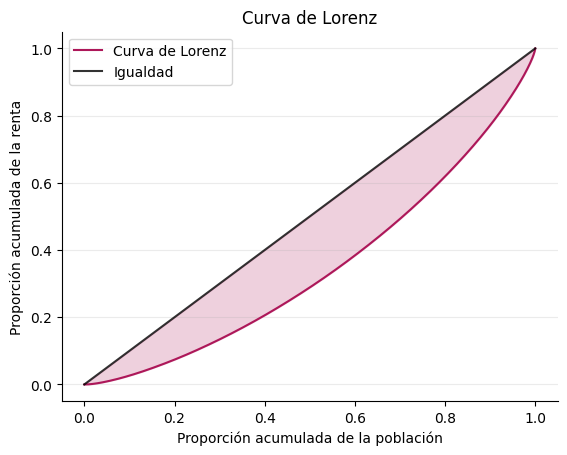

In [59]:
datos_l = Datos[Datos["rocdem"] >= 0]

renta = np.asarray(datos_l["rocdem"])
poblacion = np.asarray(datos_l["Factor"])

orden = np.argsort(renta)

renta = renta[orden]
poblacion = poblacion[orden]

renta_ponderada = renta * poblacion

rentaac = np.cumsum(renta_ponderada) / np.sum(renta_ponderada)
pobac = np.cumsum(poblacion) / np.sum(poblacion)

# Gráfico
fig, ax = plt.subplots()

ax = sns.lineplot(
    x = np.insert(pobac, 0, 0),
    y = np.insert(rentaac, 0, 0),
    color = "#AD1759",
    label = "Curva de Lorenz"
)

ax = sns.lineplot(
    x = [0,1],
    y = [0,1],
    color = "black",
    alpha = 0.8,
    label = "Igualdad"
)

# Rellenar el espacio entre ambas curvas
ax.fill_between( # argumentos(x, y1, y2)
    np.insert(pobac, 0, 0), #eje x
    np.insert(rentaac, 0, 0), # Curva de lorenz
    np.insert(pobac, 0, 0), # linea recta de igualdad
    color = "#AD1759",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xlabel("Proporción acumulada de la población")
plt.ylabel("Proporción acumulada de la renta")
plt.title("Curva de Lorenz")
plt.legend()
plt.grid(axis="y", alpha=0.25)

fig.savefig(
    "G Renta / curva de lorenz.png",
    dpi=300,
    bbox_inches="tight"
)


In [60]:
Gini = Gini_ponderado(
    Datos["rocdem"],
    Datos["Factor"]
)

f" El índice Gini de España {Gini}"

' El índice Gini de España 0.31'

Distinta renta por género y nacionalidad

In [165]:
Renta_genero = FR.groupby("genero").apply(
    lambda x: pd.Series({
        "Renta per cápita": np.average(
                    x["rentapc"],
                    weights=x["factor_r"]
                ),

        "Renta escala (OCDE)": np.average(
            x["rocdem"],
            weights=x["factor_r"]
        )
        
    })
    ).map(
        lambda x: f"{x:,.2f} €".replace(",", "X").replace(".", ",").replace("X", ".")
    ).reset_index()
Renta_genero

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\480065363.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  Renta_genero = FR.groupby("genero").apply(


,genero,Renta per cápita,Renta escala (OCDE)
0,Hombre,"15.833,15 €","23.308,41 €"
1,Mujer,"15.414,63 €","22.591,67 €"


In [189]:
R_H = np.average(
    FR[FR["genero"] == "Hombre"]["rocdem"],
    weights = FR[FR["genero"] == "Hombre"]["factor_r"]
)

R_M = np.average(
    FR[FR["genero"] == "Mujer"]["rocdem"],
    weights = FR[FR["genero"] == "Mujer"]["factor_r"]
)

In [375]:
Brecha = ((R_M - R_H) / (R_H)) * 100
f"La brecha entre generos sobre la rentas equivalents medias es igual a {Brecha:,.2f} %. "

'La brecha entre generos sobre la rentas equivalents medias es igual a -3.08 %. '

In [156]:
Renta_nacionalidad = FR.groupby("nacionalidad").apply(
    lambda x: pd.Series({
        "Renta per cápita": np.average(
                    x["rentapc"],
                    weights=x["factor_r"]
                ),

        "Renta escala (OCDE)": np.average(
            x["rocdem"],
            weights=x["factor_r"]
        )
        
    })
    ).map(
        lambda x: f"{x:,.2f} €".replace(",", "X").replace(".", ",").replace("X", ".")
    )

Renta_nacionalidad

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\3229137451.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  Renta_nacionalidad = FR.groupby("nacionalidad").apply(


,Renta per cápita,Renta escala (OCDE)
nacionalidad,,
España,"16.473,36 €","24.105,47 €"
Extranjera RM,"9.017,97 €","14.070,69 €"
Extranjera UE,"13.242,83 €","19.438,50 €"


In [376]:
R_Española = np.average(
    FR[FR["nacionalidad"] == "España"]["rocdem"],
    weights = FR[FR["nacionalidad"] == "España"]["factor_r"]
)

R_Extranjera = np.average(
    FR[FR["nacionalidad"] != "España"]["rocdem"],
    weights = FR[FR["nacionalidad"] != "España"]["factor_r"]
)

Brecha_nac = ((R_Extranjera - R_Española) / R_Española) *100

f"La breca entra las rentas equivalentes medias de la población con nacionalidad española y nacionalidad extranjera es de un {Brecha_nac:.2f} %"

'La breca entra las rentas equivalentes medias de la población con nacionalidad española y nacionalidad extranjera es de un -34.81 %'

#### Renta por CCAA y desigualdad

In [283]:
Resultado = []

for ccaa, df_ccaa in Datos.groupby(Datos["CCAA"]):
    mask = df_ccaa["rocdem"].notna() & df_ccaa["Factor"].notna()

    media = np.average(
        df_ccaa.loc[mask, "rocdem"],
        weights = df_ccaa.loc[mask, "Factor"]
    )
    
    desviacion = np.sqrt(np.average(
        (df_ccaa.loc[mask, "rocdem"] - media) ** 2,
        weights = df_ccaa.loc[mask, "Factor"]
    ))

    Resultado.append({
        "CCAA" : ccaa,
        "Renta media equivalente": media,
        "desviación típica": desviacion,
        "C.V.": desviacion / media * 100,
        "var media vs media total (%)": (media - Renta_media_equi) / Renta_media_equi * 100,
    })

RMPC_CCAA = pd.DataFrame(Resultado)
RMPC_CCAA = RMPC_CCAA.sort_values(by = "Renta media equivalente", ascending = False).reset_index(drop = True)

RMPC_CCAA.loc[len(RMPC_CCAA)] = {
    "CCAA" : "Total",
    "Renta media equivalente": Renta_media_equi,
    "desviación típica": np.sqrt(np.average(
        (Datos["rocdem"] - Renta_media_equi) ** 2,
        weights = Datos["Factor"]
    )),
    "C.V.": dt_renta_media_equi / Renta_media_equi * 100,
    "var media vs media total (%)": 0
}

RMPC_CCAA.style.format({
    "Renta media equivalente": lambda x: f"{x:,.2f}".replace(",", "."),
    "desviación típica": lambda x: f"{x:,.2f}".replace(",", "."),
    "C.V.": lambda x: f"{x:,.2f}".replace(",",".") + "%",
    "var media vs media total (%)": lambda x: f"{x:,.2f}".replace(",", ".") + "%",
})

,CCAA,Renta media equivalente,desviación típica,C.V.,var media vs media total (%)
0,País Vasco,28.761.90,15.776.12,54.85%,25.36%
1,C.Madrid,27.136.20,16.614.63,61.23%,18.28%
2,C.F. de Navarra,26.751.82,15.554.83,58.14%,16.60%
3,Cataluña,25.424.04,14.795.71,58.20%,10.81%
4,Islas Baleares,24.810.62,13.164.54,53.06%,8.14%
5,Aragón,24.297.37,12.896.28,53.08%,5.90%
6,Asturias,23.536.03,12.759.73,54.21%,2.58%
7,Cantabria,23.087.40,13.049.59,56.52%,0.63%
8,Galicia,22.632.66,12.436.60,54.95%,-1.35%
9,La Rioja,22.510.81,12.350.20,54.86%,-1.88%


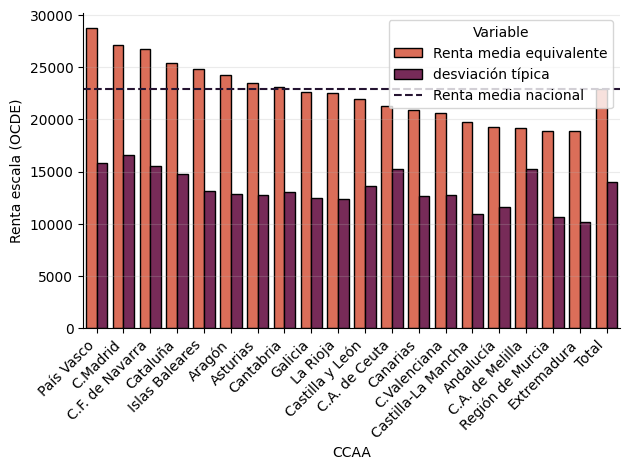

In [209]:
Datos_grafico = RMPC_CCAA.reset_index()

Datos_grafico = Datos_grafico.melt(
    id_vars="CCAA",
    value_vars=["Renta media equivalente", "desviación típica"],
    var_name = "Variable",
    value_name="Renta escala (OCDE)"
)


fig, ax = plt.subplots()

ax = sns.barplot(
    Datos_grafico,
    x = "CCAA",
    y = "Renta escala (OCDE)",
    hue = "Variable",
    palette="rocket_r",
    edgecolor = "black",
    ax = ax
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.axhline(Renta_media_equi, color = "#251432", linestyle = "--", label = "Renta media nacional" )
ax.legend(title = "Variable")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()



plt.show()

fig.savefig(
    "G Renta / rentaccaa.png",
    dpi=300,
    bbox_inches="tight"
)


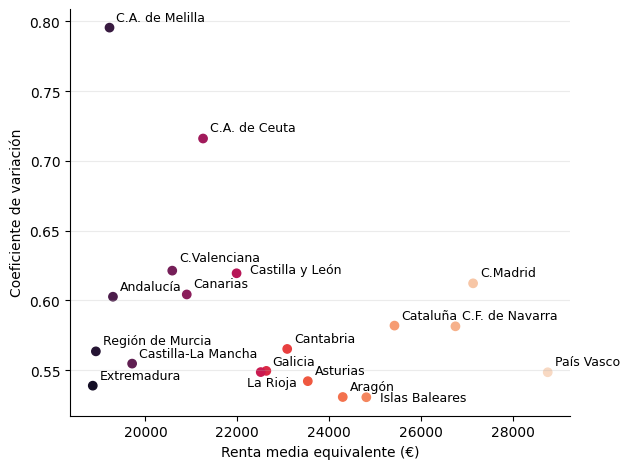

In [280]:
fig, ax = plt.subplots()

Scatter_data = RMPC_CCAA[RMPC_CCAA["CCAA"] != "Total"]
plt.scatter(
    Scatter_data["Renta media equivalente"],
    Scatter_data["C.V."],
    color=sns.color_palette(
        "rocket_r",
        n_colors=len(Scatter_data["CCAA"].unique())
    )
   
)

Desplazamientos = {
    "C.Valenciana" : (5, 7),
    "Castilla y León" : (10, 0),
    "Islas Baleares" : (10, -3),
    "Galicia" : (4, 4),
    "La Rioja": (-10, -10)
}

for _, fila in Scatter_data.iterrows():
    ax.annotate(
        fila["CCAA"],
        (fila["Renta media equivalente"], fila["C.V."]),
        xytext= Desplazamientos.get(fila["CCAA"], (5, 5)),
        textcoords="offset points",
        fontsize=9
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("Renta media equivalente (€)")
ax.set_ylabel("Coeficiente de variación")

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

fig.savefig(
    "G Renta / scatterplot.png",
    dpi=300,
    bbox_inches="tight"
)


In [350]:
Cuartiles_CCAA = Datos.groupby("CCAA").apply(
    lambda x:pd.Series(
        cuantiles_ponderados(
            x["rocdem"],
            x["Factor"]
        ),
        index = ["Q1", "Q2", "Q3"]),
    
).reset_index()

Cuartiles_CCAA.insert(
    len(Cuartiles_CCAA.columns),
    "IQR",
    Cuartiles_CCAA["Q3"] - Cuartiles_CCAA["Q1"]
)

Cuartiles_CCAA.insert(
    len(Cuartiles_CCAA.columns),
    "RSI",
    Cuartiles_CCAA["IQR"] / (Cuartiles_CCAA["Q3"] + Cuartiles_CCAA["Q1"]) *100
)

Cuartiles_CCAA = Cuartiles_CCAA.sort_values(
    by = "IQR",
    ascending = False
).reset_index(drop = True)

Cuartiles_CCAA.loc[len(Cuartiles_CCAA)] ={
    "CCAA": "Total",
    "Q1" : Q1n,
    "Q2" : Q2n,
    "Q3" : Q3n,
    "IQR" : Q3n - Q1n,
    "RSI" : (Q3n - Q1n) / (Q3n + Q1n) * 100
}


Cuartiles_CCAA.style.format({
    "Q1" : lambda x: f"{x:,.0f} €".replace(",","."),
    "Q2" : lambda x: f"{x:,.0f} €".replace(",","."),
    "Q3" : lambda x: f"{x:,.0f} €".replace(",","."),
    "IQR" : lambda x: f"{x:,.0f} €".replace(",","."),
    "RSI" : lambda x: f"{x:,.2f}" + "%" 
})



C:\Users\USER\AppData\Local\Temp\ipykernel_11696\1872276143.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  Cuartiles_CCAA = Datos.groupby("CCAA").apply(


,CCAA,Q1,Q2,Q3,IQR,RSI
0,C.A. de Melilla,7.880 €,15.878 €,27.466 €,19.586 €,55.41%
1,País Vasco,17.973 €,26.303 €,35.788 €,17.815 €,33.14%
2,C.Madrid,16.568 €,23.795 €,33.522 €,16.954 €,33.85%
3,C.F. de Navarra,17.139 €,23.654 €,33.272 €,16.133 €,32.00%
4,Cataluña,15.898 €,23.102 €,31.862 €,15.964 €,33.43%
5,Asturias,15.087 €,22.313 €,30.593 €,15.506 €,33.95%
6,C.A. de Ceuta,11.488 €,15.625 €,26.422 €,14.933 €,39.39%
7,Islas Baleares,16.356 €,22.789 €,31.276 €,14.920 €,31.32%
8,C.Valenciana,11.976 €,18.600 €,26.242 €,14.266 €,37.33%
9,Aragón,15.482 €,22.662 €,29.508 €,14.027 €,31.18%


In [301]:
Gini_CCAA = Datos.groupby("CCAA").apply(
    lambda x:pd.Series(
        Gini_ponderado(
            x["rocdem"],
            x["Factor"]
        ),
        index=["Gini"]
    )
    
).sort_values(by = "Gini", ascending=False).reset_index()
Gini_CCAA

C:\Users\USER\AppData\Local\Temp\ipykernel_11696\3129897928.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  Gini_CCAA = Datos.groupby("CCAA").apply(


,CCAA,Gini
0,C.A. de Melilla,0.400
1,C.A. de Ceuta,0.371
2,C.Valenciana,0.313
3,Andalucía,0.311
4,C.Madrid,0.305
5,Canarias,0.304
6,Región de Murcia,0.296
7,Castilla-La Mancha,0.295
8,Castilla y León,0.295
9,C.F. de Navarra,0.292


### Pobreza

In [351]:
L_pobreza = 0.6 * z50rmequi
f"La línea riesgo de pobreza son aquella población de los hogares con una renta equivalente menor a {L_pobreza.round(2):,.0f} €".replace(",", ".")

'La línea riesgo de pobreza son aquella población de los hogares con una renta equivalente menor a 12.220 €'

In [359]:
Datos["Pobre"] = np.where(
    Datos["rocdem"] <= L_pobreza,
    1,
    0
)

Peso_Pobreza = Datos.groupby("Pobre")["Factor"].sum().div(
    Datos["Factor"].sum()
).mul(100).round(2).reset_index(name="Peso (%)")

Peso_Pobreza.insert(
    len(Peso_Pobreza.columns),
    "Población",
    Datos.groupby("Pobre")["Factor"].sum()
)


Peso_Pobreza.loc[len(Peso_Pobreza["Pobre"])] = {
    "Pobre" : "Total",
    "Peso (%)" : 100,
    "Población": Peso_Pobreza["Población"].sum()
}

Peso_Pobreza.style.format({
    "Población" : lambda x: f"{x:,.2f}".replace(",", "X").replace(".",",").replace("X",".")
})


,Pobre,Peso (%),Población
0,0,80.530000,"39.218.787,10"
1,1,19.470000,"9.483.396,90"
2,Total,100.000000,"48.702.184,00"


In [373]:
# Poblacion pobre total
Poblacion_HUP_total = Datos.loc[
    Datos["Pobre"] == 1,"Factor"
    ].sum()

# Población total 
Poblacion_total = Datos["Factor"].sum()

# Población pobre por CCAA
Poblacion_HUP_CCAA = (Datos.loc[
    Datos["Pobre"] == 1]
    .groupby("CCAA")["Factor"]
    .sum())

# Población total por CCAA
Poblacion_total_CCAA = (
    Datos.groupby("CCAA")["Factor"].sum()
    )

#Crear tabla
Pobres_por_CCAA = Poblacion_HUP_CCAA.reset_index(name = "Población en riesgo de pobreza")


Pobres_por_CCAA["Distribución de la tasa de pobreza (%)"] = (
    Pobres_por_CCAA["Población en riesgo de pobreza"]
    / Poblacion_HUP_total).mul(100).round(2)

Pobres_por_CCAA["Tasa de pobreza (%)"] = (
    Datos.groupby("CCAA").apply(
        lambda x: (
            x.loc[x["Pobre"] == 1, "Factor"].sum()
            / x["Factor"].sum()
        ) * 100
    ).round(2).values
)

Pobres_por_CCAA = Pobres_por_CCAA.sort_values(
        by = "Distribución de la tasa de pobreza (%)",
        ascending = False
).reset_index(drop = True)

Pobres_por_CCAA.loc[len(Pobres_por_CCAA)] = {
    "CCAA" : "Total",
    "Población en riesgo de pobreza": Poblacion_total,
    "Distribución de la tasa de pobreza (%)" : 100,
    "Tasa de pobreza (%)" : (Poblacion_HUP_total / Poblacion_total * 100).round(2)
    }


Pobres_por_CCAA.style.format({
    "Población en riesgo de pobreza" : lambda x: f"{x:,.0f}".replace(",", "X").replace(".", ",").replace("X", "."),
    "Distribución de la tasa de pobreza (%)" : lambda x: f"{x:,.2f} % ",
    "Tasa de pobreza (%)" : lambda x: f"{x:,.2f} %"
})


C:\Users\USER\AppData\Local\Temp\ipykernel_11696\2455174165.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  Datos.groupby("CCAA").apply(


,CCAA,Población en riesgo de pobreza,Distribución de la tasa de pobreza (%),Tasa de pobreza (%)
0,Andalucía,2.390.572,25.21 %,27.74 %
1,C.Valenciana,1.398.746,14.75 %,26.00 %
2,Cataluña,1.146.636,12.09 %,14.28 %
3,C.Madrid,897.429,9.46 %,12.69 %
4,Castilla-La Mancha,546.346,5.76 %,25.93 %
5,Canarias,513.753,5.42 %,22.88 %
6,Castilla y León,470.172,4.96 %,19.80 %
7,Galicia,430.817,4.54 %,15.99 %
8,Región de Murcia,421.250,4.44 %,26.74 %
9,Extremadura,274.518,2.89 %,26.23 %


C:\Users\USER\AppData\Local\Temp\ipykernel_11696\3145240919.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


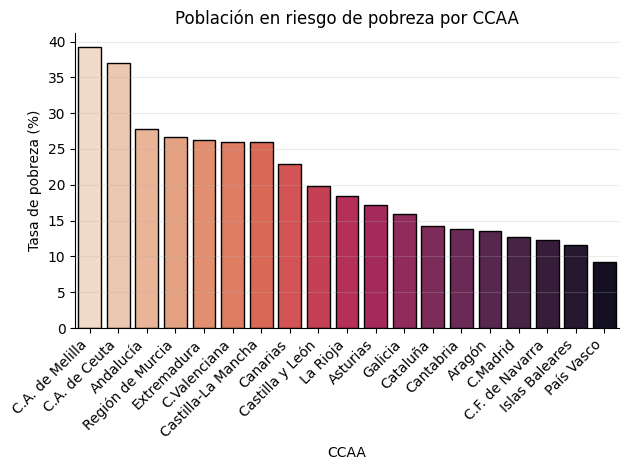

In [72]:
fig, ax = plt.subplots()

Datos_pie = Pobres_por_CCAA[Pobres_por_CCAA["CCAA"] != "Total"].sort_values(
    by = "Tasa de pobreza (%)",
            ascending = False
    ).reset_index(drop = True)


ax = sns.barplot(
    Datos_pie,
    x = "CCAA",
    y = "Tasa de pobreza (%)",
    palette="rocket_r",
    edgecolor = "black",
    ax = ax
)
ax.set_title("Población en riesgo de pobreza por CCAA")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.grid(axis="y", alpha=0.25)
plt.show()


fig.savefig(
    "G Renta / Tasa de pobreza (%) por CCAA.png",
    dpi=300,
    bbox_inches="tight"
)


Exportar gráficos

In [374]:
with pd.ExcelWriter("Tablas/Resultados_Desigualdad_ECV.xlsx") as writer:

    Descriptivos.to_excel(
        writer,
        sheet_name="Descriptivos",
        index= True
    )

    Cuartiles.to_excel(
        writer,
        sheet_name="Cuartiles",
        index= True
    )

    Renta_nacionalidad.to_excel(
        writer,
        sheet_name = "rentas por nacionalidad",
        index = True
    )

    RMPC_CCAA.to_excel(
        writer,
        sheet_name="RMPC_CCAA",
        index=False
    )

    Cuartiles_CCAA.to_excel(
        writer,
        sheet_name="Cuartiles_CCAA",
        index=False
    )

    Peso_Pobreza.to_excel(
        writer,
        sheet_name="Peso_Pobreza",
        index=False
    )

    Pobres_por_CCAA.to_excel(
        writer,
        sheet_name="Pobres_por_CCAA",
        index=False
    )